In [1]:
# Necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from datetime import datetime

from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
columns = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']

df = pd.read_csv("games.csv",names=columns, header=0)

In [3]:
df.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,About the game,...,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Developers,Publishers,Categories,Genres,Tags,Screenshots,Movies
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,0,NaN,...,0,0,0,NaN,NaN,NaN,NaN,NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,65,0,"Springtime, April: when the cherry trees come ...",...,0,8,0,minori,MangaGamer,"Single-player,Steam Trading Cards,Steam Cloud,...",Adventure,"Adventure,Visual Novel,Anime,Cute",https://shared.akamai.steamstatic.com/store_it...,NaN
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,0,"Immerse yourself in the most beloved, mystical...",...,0,0,0,Somer Games,8floor,"Single-player,Family Sharing",Casual,"Casual,Card Game,Solitaire,Puzzle,Hidden Objec...",https://shared.akamai.steamstatic.com/store_it...,NaN
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,0,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",...,0,0,0,유진게임즈,유진게임즈,"Single-player,Steam Achievements,Family Sharing","Casual,Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,0,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,0,Reality Expanded LLC,Reality Expanded LLC,"Single-player,VR Only,Steam Leaderboards,Famil...","Action,Early Access",NaN,https://shared.akamai.steamstatic.com/store_it...,NaN


In [4]:
df.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'About the game',
       'Supported languages', 'Full audio languages', 'Reviews',
       'Header image', 'Website', 'Support url', 'Support email', 'Windows',
       'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score',
       'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations',
       'Notes', 'Average playtime forever', 'Average playtime two weeks',
       'Median playtime forever', 'Median playtime two weeks', 'Developers',
       'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies'],
      dtype='str')

### Data aggregation
For our analysis, we need a dataframe of developers, not of games. For this, let us group all games that share a developer, and look at the count of games released, overall engagement, and average price for each developer.

In [5]:
df['Release date'] = pd.to_datetime(df['Release date'])
df['Effort'] = (
    df['Screenshots'].fillna('').str.count(',') + 
    df['Screenshots'].notna().astype(int) +
    df['About the game'].fillna('').str.len() / 500
)

Making so games with DLC count >= 1 are counted as another game

In [6]:
df['game_weight'] = 1 # every entry defaults to 1

df.loc[df['DLC count'] >=1, 'game_weight'] = 2 # if a game has DLC count >= 1, increase that weight to 2

In [ ]:
# Aggregate genres across all games by developer
def aggregate_genres(genres):
    unique_genres = set()
    for game_genres in genres.dropna():
        for genre in game_genres.split(','):
            unique_genres.add(genre.strip())
    return ','.join(sorted(unique_genres))
def aggregate_genres_count(genres):
    unique_genres = set()
    for game_genres in genres.dropna():
        for genre in game_genres.split(','):
            unique_genres.add(genre.strip())
    return len(unique_genres)

# Group by developer and aggregate features
developers_df = df.groupby('Developers').agg(
    game_count=('game_weight', 'sum'), # how many games released
    total_positive=('Positive', 'sum'), # total positive reviews
    total_negative=('Negative', 'sum'), # total negative reviews
    avg_price=('Price', 'mean'), # average game price
    max_success=('Positive', 'max'), # highest success in developers career
    genres=('Genres', aggregate_genres), # all the genres a developer has used
    genre_count=('Genres', aggregate_genres_count), # count of genres per developer
    start_year=('Release date', 'min'), # year of first game released
    end_year=('Release date', 'max'), # year of last game released
    avg_effort=('Effort', 'mean') # average effort put into steam pages for games
).reset_index()

In [9]:
developers_df.head()


,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088


In [10]:
developers_df['engagement'] = developers_df['total_positive'] + developers_df['total_negative']
developers_df['avg_game_success'] =developers_df['engagement'] / developers_df['game_count']

developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0


In [11]:
def get_years_active(dataframe, end_year_column, start_year_column):
    years_active_list = []
    for row in dataframe.itertuples(index=True):
        index = row[0]
        start_value = start_year_column[index].year
        end_value = end_year_column[index].year
        difference = int(end_value) - int(start_value) + 1
        years_active_list.append(difference)
    dataframe['years_active'] = years_active_list

In [12]:
get_years_active(developers_df, developers_df['end_year'], developers_df['start_year'])
developers_df['frequency'] = developers_df['game_count'] / developers_df['years_active']

In [13]:
developers_df.tail()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
72854,𝓛𝓮𝔁𝔂,2,1,0,5.99,1,"Action,Adventure,Indie",3,2022-09-14,2026-02-15,9.146,1,0.5,5,0.4
72855,𝕲𝖗𝖆𝖓𝖉𝕸𝖎𝖓𝖎 𝕾𝖙𝖚𝖉𝖎𝖔𝖘 (ᚴᛘᛋ),1,4,1,5.99,4,"Indie,Strategy",2,2021-05-16,2021-05-16,14.468,5,5.0,1,1.0
72856,👁️,1,0,0,0.00,0,Indie,1,2022-03-26,2022-03-26,8.792,0,0.0,1,1.0
72857,📚瓜山书坊Guashan Bookshop,1,6,3,149.99,6,"Adventure,Casual,Indie,RPG",4,2018-07-13,2018-07-13,8.316,9,9.0,1,1.0
72858,🧊 No-Face $hiba 🧊,1,17,10,2.99,17,"Casual,Early Access,Indie,Simulation",4,2023-08-16,2023-08-16,17.600,27,27.0,1,1.0


## Data Quality

In [14]:
developers_df.isna().sum()

Developers          0
game_count          0
total_positive      0
total_negative      0
avg_price           0
max_success         0
genres              0
genre_count         0
start_year          0
end_year            0
avg_effort          0
engagement          0
avg_game_success    0
years_active        0
frequency           0
dtype: int64

In [15]:
developers_df.duplicated().sum()

np.int64(0)

## Data Visualization

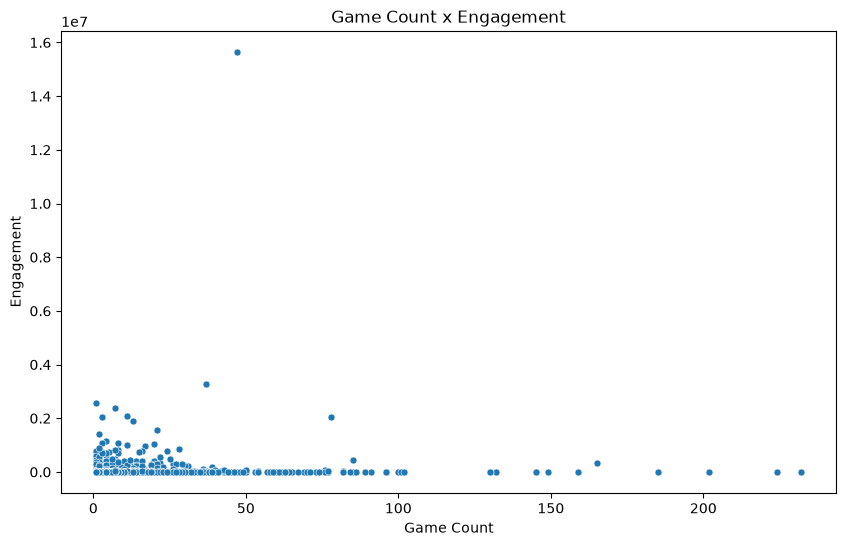

In [16]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='game_count',
    y='engagement',
    data=developers_df,
    s=25
)
plt.title('Game Count x Engagement')
plt.xlabel('Game Count')
plt.ylabel('Engagement')
plt.show()

## Jacob's graphs

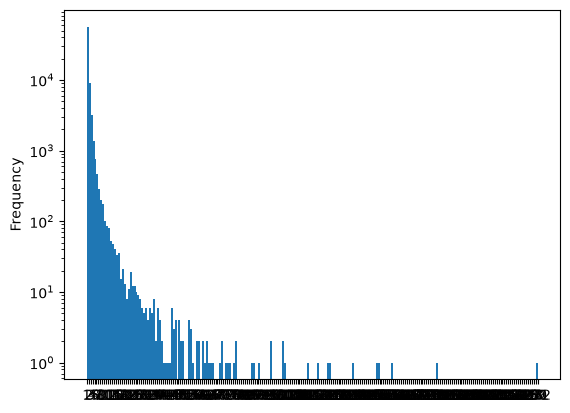

In [17]:
result = df.groupby("Developers").agg(
    positive=("Positive", "sum"),
    count=("Developers", "size")
)
maxX = round(result["count"].max())
result["count"].plot.hist(bins=range(1,maxX+1))
plt.yscale("log")
plt.xticks(range(1,maxX+1));

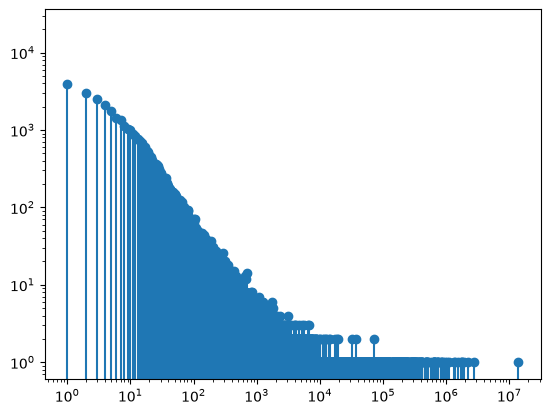

In [18]:
freq = result['positive'].value_counts().sort_index()

plt.stem(freq.index, freq.values)
plt.yscale("log")
plt.xscale("log")

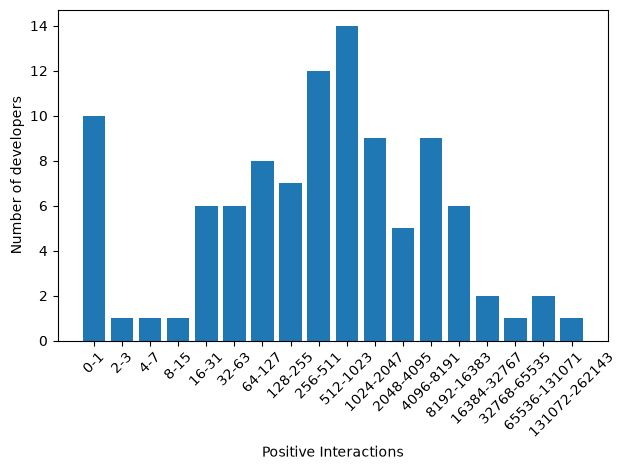

In [19]:
dev_game_four = result[result["count"] == 10]
bins = [0] + [2**i for i in range(1, int(np.ceil(np.log2(dev_game_four["positive"].max() + 1))) + 1)]
counts, edges = np.histogram(dev_game_four["positive"], bins=bins)
plt.bar(
    [f"{int(a)}-{int(b)-1}" for a, b in zip(edges[:-1], edges[1:])],
    counts
)
plt.xlabel("Positive Interactions")
plt.ylabel("Number of developers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
dev_game_four.shape

(101, 2)

## Outliers

In [21]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,max_success,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000,72859,72859,72859.000000,7.285900e+04,7.285900e+04,72859.000000,72859.000000
mean,1.858755,1.758784e+03,2.848075e+02,4.857781,1.308611e+03,3.291000,2022-01-01 21:53:54.263440,2022-09-01 07:29:23.905626,11.409789,2.043591e+03,6.294165e+02,1.661483,1.184051
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,1997-06-30 00:00:00,2003-11-01 00:00:00,0.000000,0.000000e+00,0.000000e+00,1.000000,0.100000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,2.000000,2019-09-23 00:00:00,2020-09-30 00:00:00,7.606000,0.000000e+00,0.000000e+00,1.000000,1.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,6.000000e+00,3.000000,2022-10-18 00:00:00,2023-08-14 00:00:00,9.887000,8.000000e+00,7.000000e+00,1.000000,1.000000
75%,2.000000,4.800000e+01,1.300000e+01,5.990000,4.100000e+01,4.000000,2024-10-24 00:00:00,2025-03-06 00:00:00,13.368000,6.400000e+01,4.058571e+01,1.000000,1.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,7.642084e+06,20.000000,2026-12-01 00:00:00,2026-12-01 00:00:00,209.526000,1.564624e+07,2.557944e+06,27.000000,74.500000
std,3.712594,5.793022e+04,9.118371e+03,9.637942,3.448315e+04,1.574045,NaN,NaN,6.038973,6.621155e+04,1.314414e+04,1.853833,0.809167


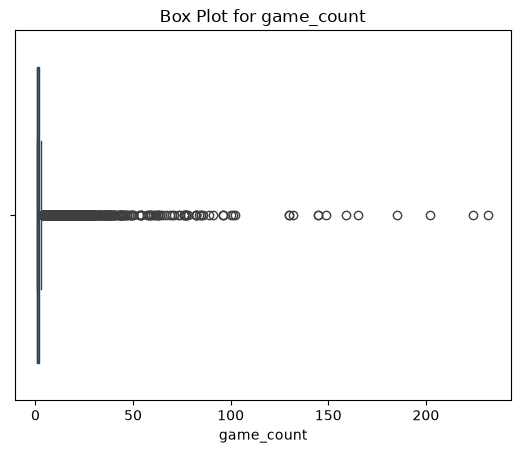

In [22]:
sns.boxplot(x=developers_df['game_count'])
plt.title("Box Plot for game_count")
plt.show()

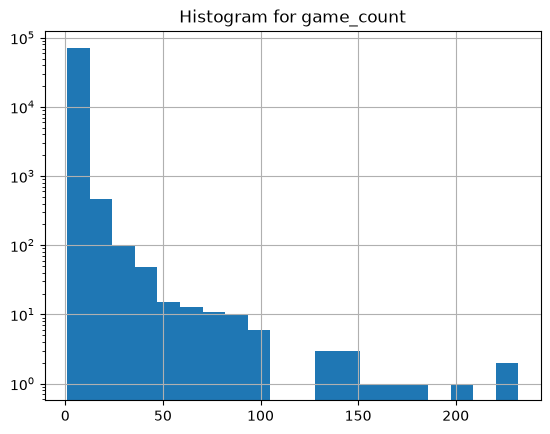

In [23]:
developers_df['game_count'].hist(bins=20, log=True)
plt.title("Histogram for game_count")
plt.show()

In [24]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,max_success,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000,72859,72859,72859.000000,7.285900e+04,7.285900e+04,72859.000000,72859.000000
mean,1.858755,1.758784e+03,2.848075e+02,4.857781,1.308611e+03,3.291000,2022-01-01 21:53:54.263440,2022-09-01 07:29:23.905626,11.409789,2.043591e+03,6.294165e+02,1.661483,1.184051
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,1997-06-30 00:00:00,2003-11-01 00:00:00,0.000000,0.000000e+00,0.000000e+00,1.000000,0.100000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,2.000000,2019-09-23 00:00:00,2020-09-30 00:00:00,7.606000,0.000000e+00,0.000000e+00,1.000000,1.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,6.000000e+00,3.000000,2022-10-18 00:00:00,2023-08-14 00:00:00,9.887000,8.000000e+00,7.000000e+00,1.000000,1.000000
75%,2.000000,4.800000e+01,1.300000e+01,5.990000,4.100000e+01,4.000000,2024-10-24 00:00:00,2025-03-06 00:00:00,13.368000,6.400000e+01,4.058571e+01,1.000000,1.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,7.642084e+06,20.000000,2026-12-01 00:00:00,2026-12-01 00:00:00,209.526000,1.564624e+07,2.557944e+06,27.000000,74.500000
std,3.712594,5.793022e+04,9.118371e+03,9.637942,3.448315e+04,1.574045,NaN,NaN,6.038973,6.621155e+04,1.314414e+04,1.853833,0.809167


In [25]:
z = np.abs(stats.zscore(developers_df['game_count']))
outliers_game_count = developers_df[z > 3]
outliers_game_count.shape

(684, 15)

In [26]:
outliers_game_count.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
53,07th Expansion,14,15272,604,8.019286,5114,"Action,Adventure,Casual,Indie",4,2015-05-15,2023-11-09,10.550000,15876,1134.000000,9,1.555556
86,"100 Cozy Games,Cats",82,33,1,0.891220,33,"Action,Adventure,Casual,Free To Play,Indie,RPG...",9,2023-12-17,2026-02-09,14.024683,34,0.414634,4,20.500000
116,10tons Ltd,22,9303,1051,4.210588,2778,"Action,Adventure,Casual,Indie,RPG,Simulation,S...",8,2014-06-11,2023-03-30,12.627529,10354,470.636364,10,2.200000
118,11 bit studios,14,231666,22877,6.131000,114315,"Action,Adventure,Free To Play,Indie,Simulation...",7,2011-04-08,2025-06-13,15.994600,254543,18181.642857,15,0.933333
164,16air,16,73,13,1.240769,20,"Action,Adventure,Casual,Indie,RPG,Simulation,S...",7,2018-09-04,2025-10-23,10.854923,86,5.375000,8,2.000000


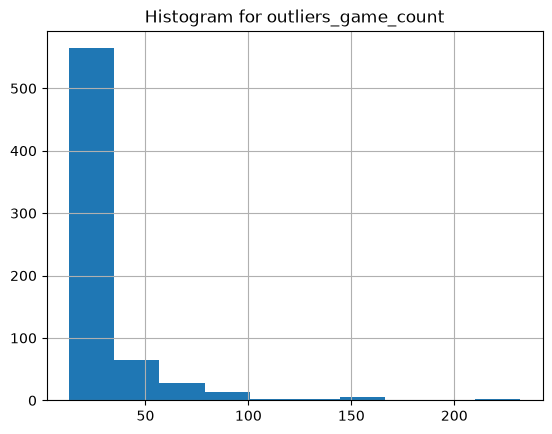

In [27]:
outliers_game_count['game_count'].hist(bins=10)
plt.title("Histogram for outliers_game_count")
plt.show()

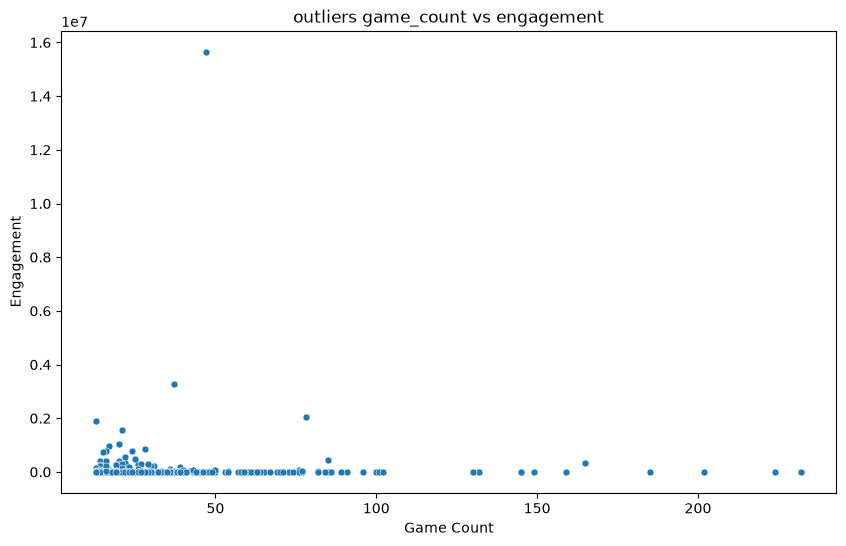

In [28]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=outliers_game_count,
    x='game_count',
    y='engagement',
    s=25
)
plt.title('outliers game_count vs engagement')
plt.xlabel('Game Count')
plt.ylabel('Engagement')
plt.show()

In [29]:
z = np.abs(stats.zscore(developers_df['engagement']))
outliers_engagement = developers_df[z > 3]
outliers_engagement.shape


(124, 15)

In [30]:
outliers_engagement.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
118,11 bit studios,14,231666,22877,6.131000,114315,"Action,Adventure,Free To Play,Indie,Simulation...",7,2011-04-08,2025-06-13,15.9946,254543,18181.642857,15,0.933333
301,24 Entertainment,2,225960,98967,0.000000,225960,"Action,Adventure,Free To Play,Massively Multip...",4,2021-08-11,2021-08-11,28.2080,324927,162463.500000,1,2.000000
456,"343 Industries,Splash Damage,Ruffian Games,Bun...",5,223635,18432,2.497500,223635,Action,1,2019-12-03,2022-09-06,5.2455,242067,48413.400000,4,1.250000
618,4A Games,6,274022,28356,3.240000,108945,Action,1,2014-08-25,2020-02-14,14.7360,302378,50396.333333,7,0.857143
1444,ATLUS,26,292378,18534,18.456667,99657,"Action,Adventure,RPG,Strategy",4,2019-01-10,2025-06-18,13.8504,310912,11958.153846,7,3.714286


In [31]:
Q1_game_count = developers_df['game_count'].quantile(0.25)
Q3_game_count = developers_df['game_count'].quantile(0.75)
IQR_game_count = Q3_game_count - Q1_game_count

lower_bound_game_count = Q1_game_count - 1.5 * IQR_game_count
upper_bound_game_count = Q3_game_count + 1.5 * IQR_game_count


outliers_game_count = developers_df[(developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count)]
outliers_game_count.shape

(5783, 15)

In [32]:
Q1_engagement = developers_df['engagement'].quantile(0.25)
Q3_engagement = developers_df['engagement'].quantile(0.75)
IQR_engagement = Q3_engagement - Q1_engagement

lower_bound_engagement = Q1_engagement - 1.5 * IQR_engagement
upper_bound_engagement = Q3_engagement + 1.5 * IQR_engagement

outliers_engagement = developers_df[(developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement)]
outliers_engagement

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency
8,#workshop,6,9127,361,2.350000,3889,"Adventure,Casual,Indie",3,2019-02-27,2020-03-16,8.384667,9488,1581.333333,2,3.000000
18,"+Mpact Games, LLC.",2,172,56,0.000000,172,"Action,Adventure,Indie",3,2021-09-14,2021-09-14,20.620000,228,114.000000,1,2.000000
30,.GRAVITY,1,352,80,17.490000,352,"Adventure,Casual,Early Access,Indie,RPG,Simula...",6,2025-05-01,2025-05-01,24.776000,432,432.000000,1,1.000000
35,//commentout,2,440,49,7.190000,440,"Action,Indie",2,2022-06-01,2022-06-01,19.414000,489,244.500000,1,2.000000
38,0 Deer Soft,8,1150,250,2.976667,406,"Adventure,Casual,Free To Play,Indie",4,2021-09-17,2024-07-19,8.243000,1400,175.000000,4,2.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72745,鸽屋谷,1,242,0,2.990000,242,"Casual,Early Access,Indie,RPG,Simulation",5,2020-10-17,2020-10-17,9.872000,242,242.000000,1,1.000000
72747,鹊思网络,1,122,118,1.880000,122,"Casual,Indie,Simulation",3,2020-10-27,2020-10-27,10.850000,240,240.000000,1,1.000000
72756,黄昏フロンティア,3,2475,323,20.990000,1758,"Action,Casual,Indie",3,2018-01-05,2021-10-29,8.728667,2798,932.666667,4,0.750000
72835,유진게임즈,19,293,31,2.994615,187,"Casual,Free To Play,Indie,Simulation,Strategy",5,2020-09-03,2025-03-12,10.459077,324,17.052632,6,3.166667


In [33]:
outliers_either = developers_df[(developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement) | (developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count)]

outliers_either.shape

(14796, 15)

In [34]:
outliers_both = developers_df[((developers_df['engagement'] < lower_bound_engagement) | (developers_df['engagement'] > upper_bound_engagement)) & ((developers_df['game_count'] < lower_bound_game_count) | (developers_df['game_count'] > upper_bound_game_count))]

outliers_both.shape

(3547, 15)

## C. Preprocessing

In [35]:
columns_to_drop = ['Estimated owners', 'Peak CCU', 'Required age', 'Discount', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email','Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Score rank', 'Achievements', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Publishers', 'Categories', 'Tags'  ]
essential_attributes_df = df.drop(columns=columns_to_drop)

essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies', 'Effort', 'game_weight'],
      dtype='str')

### Processing missing entries

In [36]:
essential_attributes_df.shape


(125855, 15)

In [37]:
essential_attributes_df = essential_attributes_df.dropna(subset=['Developers']) 

In [38]:
essential_attributes_df['Developers'].isna().sum()

np.int64(0)

In [39]:
essential_attributes_df['Developers'].isnull().sum()

np.int64(0)

In [40]:
essential_attributes_df.shape


(117406, 15)

## D. Exploratory Data Analysis

## E. Pattern Discovery

In [41]:
essential_attributes_df.shape

(117406, 15)

In [42]:
essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies', 'Effort', 'game_weight'],
      dtype='str')

In [43]:
essential_attributes_df.columns

Index(['AppID', 'Name', 'Release date', 'Price', 'DLC count', 'About the game',
       'Positive', 'Negative', 'Recommendations', 'Developers', 'Genres',
       'Screenshots', 'Movies', 'Effort', 'game_weight'],
      dtype='str')

## K-Means on 2 features

To keep our data 2-dimensional, let us only first look at engagement (the sum of positive and negative reviews) and the game count

In [44]:
kmeans_df = developers_df[['game_count', 'engagement']].copy()
kmeans_df = kmeans_df.dropna() # dropping all missing entries for now, later we will revisit this

Scaling our features

In [45]:
scaler = StandardScaler()
kmeans_df_scaled = scaler.fit_transform(kmeans_df)

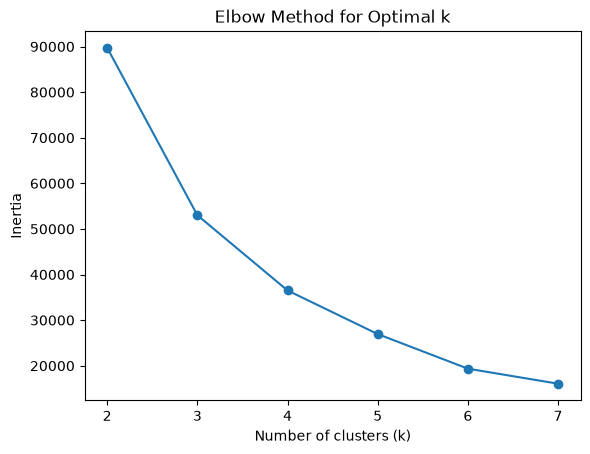

In [46]:
inertia = []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

For now, let us go with K = 4

In [47]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_df_scaled)

# adding the cluster labels back to our developers dataframe
developers_df.loc[kmeans_df.index, 'Cluster'] = clusters
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0


In [48]:
developers_df.describe()

,game_count,total_positive,total_negative,avg_price,max_success,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
count,72859.000000,7.285900e+04,7.285900e+04,72859.000000,7.285900e+04,72859.000000,72859,72859,72859.000000,7.285900e+04,7.285900e+04,72859.000000,72859.000000,72859.000000
mean,1.858755,1.758784e+03,2.848075e+02,4.857781,1.308611e+03,3.291000,2022-01-01 21:53:54.263440,2022-09-01 07:29:23.905626,11.409789,2.043591e+03,6.294165e+02,1.661483,1.184051,0.052979
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,1997-06-30 00:00:00,2003-11-01 00:00:00,0.000000,0.000000e+00,0.000000e+00,1.000000,0.100000,0.000000
25%,1.000000,0.000000e+00,0.000000e+00,0.990000,0.000000e+00,2.000000,2019-09-23 00:00:00,2020-09-30 00:00:00,7.606000,0.000000e+00,0.000000e+00,1.000000,1.000000,0.000000
50%,1.000000,6.000000e+00,1.000000e+00,2.990000,6.000000e+00,3.000000,2022-10-18 00:00:00,2023-08-14 00:00:00,9.887000,8.000000e+00,7.000000e+00,1.000000,1.000000,0.000000
75%,2.000000,4.800000e+01,1.300000e+01,5.990000,4.100000e+01,4.000000,2024-10-24 00:00:00,2025-03-06 00:00:00,13.368000,6.400000e+01,4.058571e+01,1.000000,1.000000,0.000000
max,232.000000,1.377616e+07,1.870072e+06,999.980000,7.642084e+06,20.000000,2026-12-01 00:00:00,2026-12-01 00:00:00,209.526000,1.564624e+07,2.557944e+06,27.000000,74.500000,3.000000
std,3.712594,5.793022e+04,9.118371e+03,9.637942,3.448315e+04,1.574045,NaN,NaN,6.038973,6.621155e+04,1.314414e+04,1.853833,0.809167,0.393151


In [49]:
cluster_summary = developers_df.groupby('Cluster')[['game_count','engagement']].mean()
print(cluster_summary)

         game_count    engagement
Cluster                          
0.0        1.548419  9.218784e+02
1.0       47.000000  1.564624e+07
2.0       95.089286  5.444214e+04
3.0       15.421137  5.142984e+04


In [50]:
print(developers_df['Cluster'].value_counts())

Cluster
0.0    71553
3.0     1249
2.0       56
1.0        1
Name: count, dtype: int64


In [51]:
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,0.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0


## Testing K-Means with all features

In [52]:
developers_df.columns

Index(['Developers', 'game_count', 'total_positive', 'total_negative',
       'avg_price', 'max_success', 'genres', 'genre_count', 'start_year',
       'end_year', 'avg_effort', 'engagement', 'avg_game_success',
       'years_active', 'frequency', 'Cluster'],
      dtype='str')

In [55]:
scaler = StandardScaler()

kmeans_df = developers_df[['game_count', 'total_positive', 'total_negative', 'avg_price', 'max_success', 'genre_count', 'avg_game_success', 'years_active','frequency']].copy()

kmeans_df_scaled_all_features = scaler.fit_transform(kmeans_df)
# kmeans_df.head()

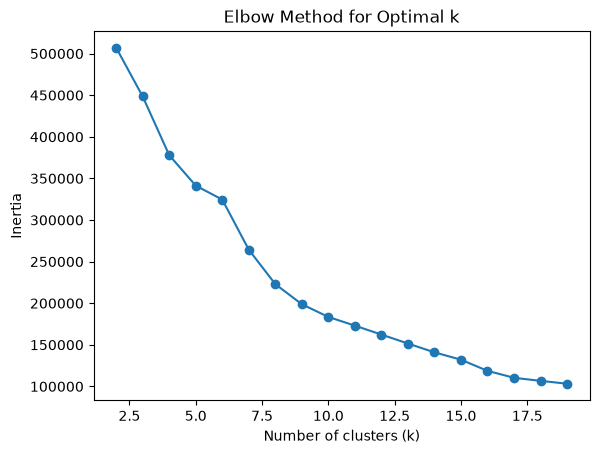

In [56]:
inertia = []
K_range = range(2, 20)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled_all_features)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

In [57]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_df_scaled_all_features)

# adding the cluster labels back to our developers dataframe
developers_df.loc[kmeans_df.index, 'Cluster'] = clusters
developers_df.head()


,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,3.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,4.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,4.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,4.0


In [58]:
cluster_summary = developers_df.groupby('Cluster')[['game_count', 'total_positive', 'total_negative', 'avg_price', 'max_success', 'genre_count', 'avg_game_success', 'years_active','frequency']].mean()
print(cluster_summary)

         game_count  total_positive  total_negative  avg_price   max_success  \
Cluster                                                                        
0.0        1.474151    3.097376e+02    6.864783e+01   4.278191  2.920465e+02   
1.0       47.000000    1.377616e+07    1.870072e+06   1.508571  7.642084e+06   
2.0       67.728972    5.275187e+04    1.079128e+04   8.778071  1.731554e+04   
3.0        5.959331    1.476961e+04    2.293634e+03   5.446917  1.065182e+04   
4.0        1.102584    2.054412e+02    3.728375e+01   4.367378  1.954930e+02   
5.0        2.725660    2.011803e+03    3.344102e+02   7.788321  1.907348e+03   

         genre_count  avg_game_success  years_active  frequency  
Cluster                                                          
0.0         4.807407        230.628927      1.394340   1.078274  
1.0         7.000000     332898.617021     25.000000   1.880000  
2.0         6.616822       1370.935251      6.392523  13.020892  
3.0         4.829733       43

In [59]:
print(developers_df['Cluster'].value_counts())

Cluster
4.0    36955
0.0    21413
5.0     9244
3.0     5139
2.0      107
1.0        1
Name: count, dtype: int64


In [60]:
whoareyou = developers_df[developers_df['Cluster'] == 1.0]
whoareyou.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
61807,Valve,47,13776163,1870072,1.508571,7642084,"Action,Adventure,Animation & Modeling,Casual,F...",7,1998-11-19,2022-03-01,10.371829,15646235,332898.617021,25,1.88,1.0


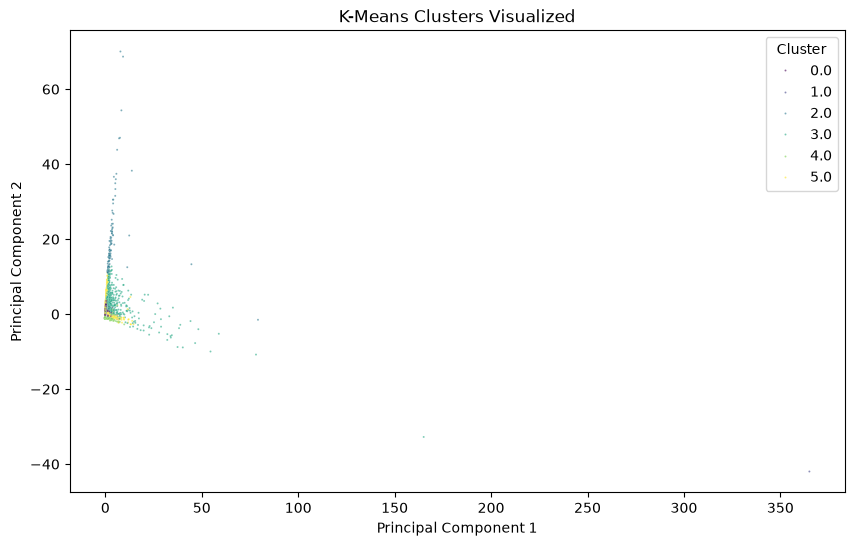

In [62]:
# reducing the scaled features to 2 dimensions
pca = PCA(n_components=2)
components = pca.fit_transform(kmeans_df_scaled_all_features)

# creating a temporary dataframe for plotting
plot_df = pd.DataFrame(components, columns=['PC1', 'PC2'])
plot_df['Cluster'] = developers_df.loc[kmeans_df.index, 'Cluster'].values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_df, 
    palette='viridis', 
    alpha=0.6,
    s=2
)
plt.title('K-Means Clusters Visualized')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

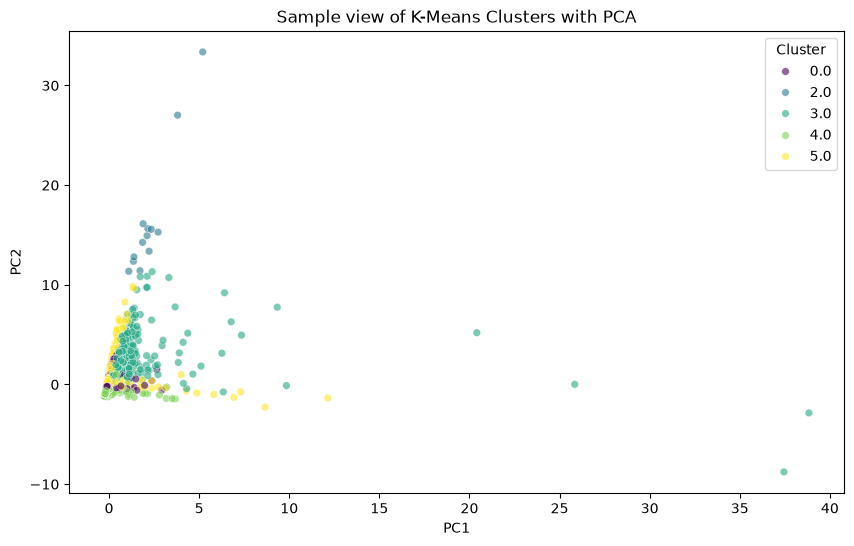

In [63]:
# sampling 10.000 developers
plot_sample = plot_df.sample(n=10000, random_state=52)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_sample, 
    palette='viridis', 
    alpha=0.6,
    s=30
)
plt.title('Sample view of K-Means Clusters with PCA')
plt.show()

In [64]:
regulars = developers_df[developers_df['Cluster'] != 2.0]
regulars = regulars[regulars['Cluster'] != 1.0]
print(regulars['Cluster'].value_counts())

Cluster
4.0    36955
0.0    21413
5.0     9244
3.0     5139
Name: count, dtype: int64


## K-Means but no price

In [65]:
scaler = StandardScaler()

regulars_kmeans = regulars[['game_count', 'total_positive', 'total_negative', 'max_success', 'avg_effort', 'avg_game_success', 'years_active','frequency']].copy()

kmeans_regulars_df_scaled_all_features = scaler.fit_transform(regulars_kmeans)

# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters = kmeans.fit_predict(kmeans_regulars_df_scaled_all_features)

# adding the cluster labels back to our developers dataframe
developers_df.loc[regulars_kmeans.index, 'Cluster'] = clusters
developers_df.head()


,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,4.0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0


In [66]:
cluster_summary = developers_df.groupby('Cluster')[['game_count', 'total_positive', 'total_negative', 'max_success', 'avg_effort', 'avg_game_success', 'years_active','frequency']].mean()
print(cluster_summary)

         game_count  total_positive  total_negative   max_success  avg_effort  \
Cluster                                                                         
0.0        1.125718    1.473703e+02    2.890647e+01  1.427846e+02    9.796883   
1.0        8.125000    1.129381e+06    1.550277e+05  8.021078e+05   16.529197   
2.0       23.606211    1.654341e+04    3.194856e+03  6.506742e+03   10.781960   
3.0        1.000000    1.520457e+06    1.037487e+06  1.520457e+06   22.876000   
4.0        4.628238    6.089011e+03    9.052596e+02  4.261348e+03   12.868609   
5.0        2.101255    1.674784e+03    2.792355e+02  1.625362e+03   16.373728   

         avg_game_success  years_active  frequency  
Cluster                                             
0.0          1.560458e+02      1.157357   0.993019  
1.0          2.655370e+05      8.150000   1.176801  
2.0          8.014137e+02      5.684472   5.269502  
3.0          2.557944e+06      1.000000   1.000000  
4.0          1.352933e+03      6.

In [67]:
interest = developers_df[developers_df['Cluster'] == 0.0]
interest['max_success'].max()

np.int64(119152)

In [68]:
interest.nlargest(5, 'total_positive')

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster
46540,"QLOC,FromSoftware, Inc.",1,119152,10147,39.99,119152,Action,1,2018-05-23,2018-05-23,7.010,129299,129299.0,1,1.0,0.0
24112,Guerrilla,1,110049,15148,0.00,110049,"Action,Adventure,RPG",3,2020-08-07,2020-08-07,6.690,125197,125197.0,1,1.0,0.0
51168,Scopely,1,108841,19170,0.00,108841,"Action,Casual,Free To Play,Indie,Massively Mul...",6,2021-10-07,2021-10-07,9.978,128011,128011.0,1,1.0,0.0
16892,EA Canada & EA Romania,1,97293,23578,0.00,97293,"Simulation,Sports",2,2021-10-01,2021-10-01,9.734,120871,120871.0,1,1.0,0.0
33100,Leppsoft,1,84918,3466,3.99,84918,"Audio Production,Utilities",2,2017-09-30,2017-09-30,11.202,88384,88384.0,1,1.0,0.0


In [69]:
developers_df['Cluster'].value_counts()

Cluster
0.0    51202
5.0    14982
4.0     5829
2.0      805
1.0       40
3.0        1
Name: count, dtype: int64

### Adding a succesful tag to each developer 

In [70]:
developers_df['succesful'] = 0
developers_df.loc[developers_df['max_success'] >=1000, 'succesful'] = 1

In [71]:
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster,succesful
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,4.0,0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0,0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0,0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0,0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0,0


## Capping price and game count

In [72]:
developers_df['game_count'] = developers_df['game_count'].clip(upper=10)
developers_df['avg_price'] = developers_df['avg_price'].clip(upper=100)

In [73]:
developers_df.head()

,Developers,game_count,total_positive,total_negative,avg_price,max_success,genres,genre_count,start_year,end_year,avg_effort,engagement,avg_game_success,years_active,frequency,Cluster,succesful
0,!CyberApex (SkagoGames),4,2,0,0.723333,1,"Action,Adventure,Casual,Indie,Simulation",5,2021-02-05,2025-07-01,8.656,2,0.5,5,0.8,4.0,0
1,!ReTigma Studio,1,2,0,15.000000,2,"Action,Adventure,Indie,RPG",4,2024-02-14,2024-02-14,5.764,2,2.0,1,1.0,0.0,0
2,#12,1,3,0,0.990000,3,"Action,Casual,Indie",3,2019-08-14,2019-08-14,6.796,3,3.0,1,1.0,0.0,0
3,#30A6D-S (Kuma),1,8,1,1.240000,8,"Adventure,Indie,RPG",3,2025-05-22,2025-05-22,17.824,9,9.0,1,1.0,0.0,0
4,#FF0000,1,42,2,1.990000,42,"Casual,Indie",2,2022-03-08,2022-03-08,14.088,44,44.0,1,1.0,0.0,0


## Stuff done 11/11

In [74]:
new_df = developers_df[developers_df['Cluster'] != 1.0]
new_df = new_df[['Developers','game_count','engagement', 'Cluster']].copy()

In [75]:
new_df

,Developers,game_count,engagement,Cluster
0,!CyberApex (SkagoGames),4,2,4.0
1,!ReTigma Studio,1,2,0.0
2,#12,1,3,0.0
3,#30A6D-S (Kuma),1,9,0.0
4,#FF0000,1,44,0.0
...,...,...,...,...
72854,𝓛𝓮𝔁𝔂,2,1,4.0
72855,𝕲𝖗𝖆𝖓𝖉𝕸𝖎𝖓𝖎 𝕾𝖙𝖚𝖉𝖎𝖔𝖘 (ᚴᛘᛋ),1,5,0.0
72856,👁️,1,0,0.0
72857,📚瓜山书坊Guashan Bookshop,1,9,0.0


In [76]:
# making a temporary df for the plotting
scaled_plot_df = pd.DataFrame(new_df, columns = ['scaled_game_count', 'scaled_engagement'])
scaled_plot_df['Cluster'] = new_df['Cluster'].values
scaled_plot_df.head()

,scaled_game_count,scaled_engagement,Cluster
0,NaN,NaN,4.0
1,NaN,NaN,0.0
2,NaN,NaN,0.0
3,NaN,NaN,0.0
4,NaN,NaN,0.0


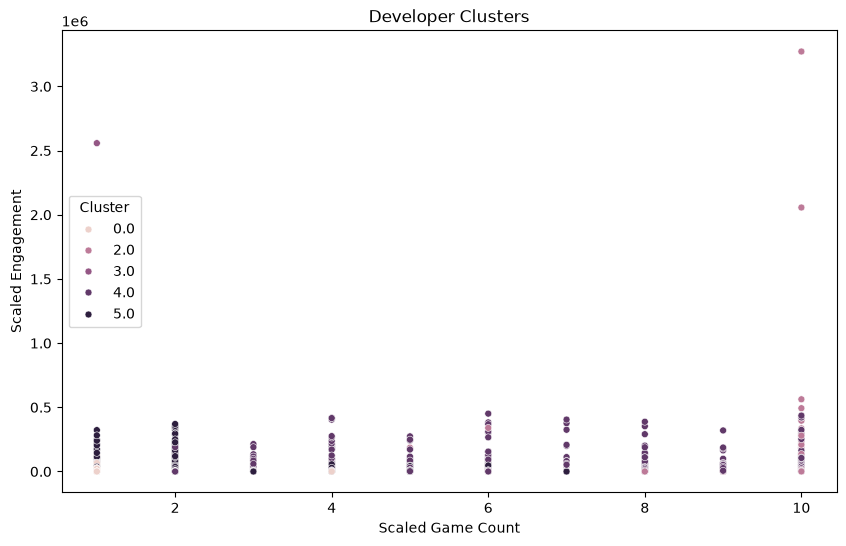

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    x='game_count',
    y='engagement',
    hue='Cluster',
    data=new_df,
    s=25
)
plt.title('Developer Clusters')
plt.xlabel('Scaled Game Count')
plt.ylabel('Scaled Engagement')
plt.legend(title='Cluster')
plt.show()

In [83]:
interest = new_df[new_df['Cluster'] == 0.0]
interest

,Developers,game_count,engagement,Cluster
1,!ReTigma Studio,1,2,0.0
2,#12,1,3,0.0
3,#30A6D-S (Kuma),1,9,0.0
4,#FF0000,1,44,0.0
5,#NVJOB,1,6,0.0
...,...,...,...,...
72853,＼上／,1,2,0.0
72855,𝕲𝖗𝖆𝖓𝖉𝕸𝖎𝖓𝖎 𝕾𝖙𝖚𝖉𝖎𝖔𝖘 (ᚴᛘᛋ),1,5,0.0
72856,👁️,1,0,0.0
72857,📚瓜山书坊Guashan Bookshop,1,9,0.0


In [84]:
interest = pd.DataFrame(interest, columns = ['game_count','engagement'])
interest

,game_count,engagement
1,1,2
2,1,3
3,1,9
4,1,44
5,1,6
...,...,...
72853,1,2
72855,1,5
72856,1,0
72857,1,9


In [86]:
kmeans_10 = KMeans(
    n_clusters=10,
    random_state=21,
    n_init='auto'
)

interest_df_scaled = scaler.fit_transform(interest)
clusters = kmeans_10.fit_predict(interest_df_scaled)

# adding the cluster labels back to our developers dataframe
interest.loc[interest.index, 'Cluster'] = clusters
interest['log_engagement'] = np.log10(interest['engagement'])
interest.head()

/home/mango/BSU/fall26/dataMining/finalProject/.venv/lib64/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,game_count,engagement,Cluster,log_engagement
1,1,2,0.0,0.301030
2,1,3,0.0,0.477121
3,1,9,0.0,0.954243
4,1,44,0.0,1.643453
5,1,6,0.0,0.778151


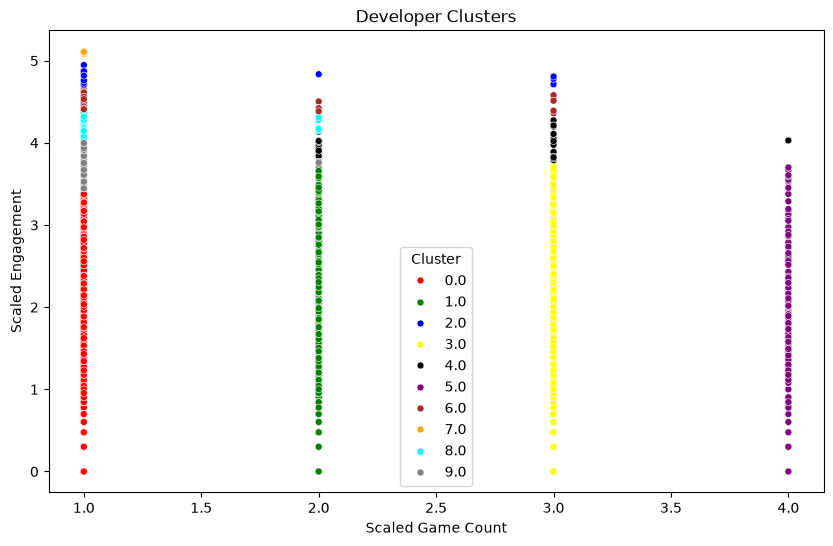

In [87]:
plt.figure(figsize=(10,6))

colors = ['red','green','blue','yellow','black','purple','brown','orange','cyan', 'grey']

sns.scatterplot(
    x='game_count',
    y='log_engagement',
    hue='Cluster',
    palette=colors,
    data=interest,
    s=25
)
plt.title('Developer Clusters')
plt.xlabel('Scaled Game Count')
plt.ylabel('Scaled Engagement')
plt.legend(title='Cluster')
plt.show()

In [ ]:
print(interest['Cluster'].value_counts())

Cluster
0.0    56599
5.0     8809
8.0     4438
2.0     1435
9.0      607
1.0      327
4.0      214
7.0      108
6.0      103
3.0       54
Name: count, dtype: int64


Now let's take average price also into consideration

In [89]:
# new df for k-means, but taking avg_price into consideration
kmeans_df_price = developers_df[['game_count', 'engagement', 'avg_price']].copy()

#applying scaling
kmeans_df_price_scaled = scaler.fit_transform(kmeans_df_price)

# using our k-means algorithm and passing our scaled np array
clusters_price = kmeans.fit_predict(kmeans_df_price_scaled)

# making a  copy of the developers df, but replacing the cluster labels
copy_df = developers_df.copy()
copy_df.loc[kmeans_df_price.index, 'Clusters'] = clusters_price

# turning the scaled np array into a proper dataframe
price_plot_df = pd.DataFrame(kmeans_df_price_scaled, columns = ['scaled_game_count', 'scaled_engagement','scaled_avg_price'])
price_plot_df['Cluster'] = copy_df['Cluster'].values
print(price_plot_df['Cluster'].value_counts())


Cluster
0.0    51202
5.0    14982
4.0     5829
2.0      805
1.0       40
3.0        1
Name: count, dtype: int64


To easily plot and visualize our clusters, we must apply PCA - Principal Component Analysis - to reduce our dimensionality

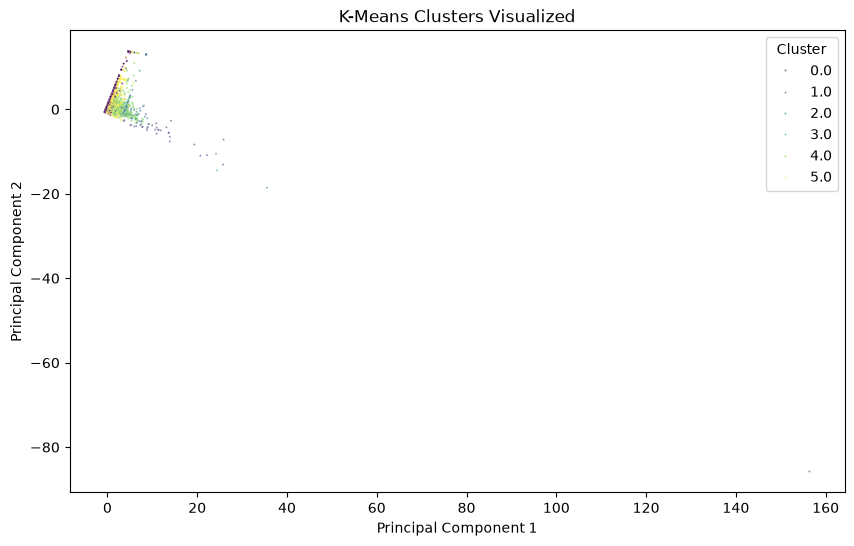

In [90]:
# reducing the scaled features to 2 dimensions
pca = PCA(n_components=2)
components = pca.fit_transform(kmeans_df_price_scaled)

# creating a temporary dataframe for plotting
plot_df = pd.DataFrame(components, columns=['PC1', 'PC2'])
plot_df['Cluster'] = developers_df.loc[kmeans_df.index, 'Cluster'].values

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_df, 
    palette='viridis', 
    alpha=0.6,
    s=2
)
plt.title('K-Means Clusters Visualized')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

Let us try to zoom in a bit, by sampling a bit of this data

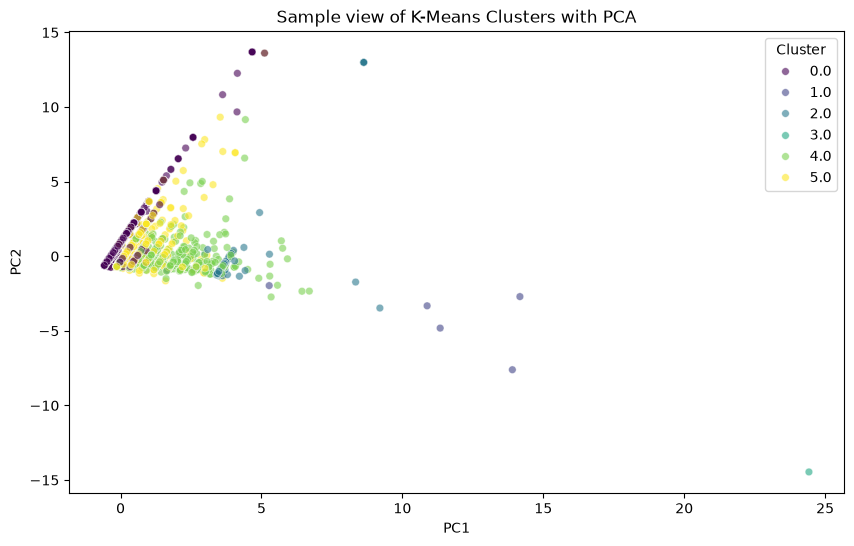

In [91]:
# sampling 10.000 developers
plot_sample = plot_df.sample(n=10000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Cluster', 
    data=plot_sample, 
    palette='viridis', 
    alpha=0.6,
    s=30
)
plt.title('Sample view of K-Means Clusters with PCA')
plt.show()

It looks like we lost one of the clusters, as we saw previously that cluster 1.0 had only one developer

## F. Evaluation

## G. Decision Sensitivity Analysis

## H. Interpretation